imports librays


In [95]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import joblib

uppload dataset

In [34]:
df = pd.read_csv("../data/raw/country_wise_latest.csv")
print("Shape before:", df.shape)

Shape before: (187, 15)


In [35]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
df.info()

# First 5 rows
display(df.head())

# Last 5 rows
display(df.tail())

Dataset Shape: (187, 15)

Column Names:
Index(['Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases',
       'Recovered / 100 Cases', 'Deaths / 100 Recovered',
       'Confirmed last week', '1 week change', '1 week % increase',
       'WHO Region'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country/Region          187 non-null    str    
 1   Confirmed               187 non-null    int64  
 2   Deaths                  187 non-null    int64  
 3   Recovered               187 non-null    int64  
 4   Active                  187 non-null    int64  
 5   New cases               187 non-null    int64  
 6   New deaths              187 non-null    int64  
 7   New recovered           187 non-null    int64  
 8   Deaths / 100 Cases  

,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
182,West Bank and Gaza,10621,78,3752,6791,152,2,0,0.73,35.33,2.08,8916,1705,19.12,Eastern Mediterranean
183,Western Sahara,10,1,8,1,0,0,0,10.00,80.00,12.50,10,0,0.00,Africa
184,Yemen,1691,483,833,375,10,4,36,28.56,49.26,57.98,1619,72,4.45,Eastern Mediterranean
185,Zambia,4552,140,2815,1597,71,1,465,3.08,61.84,4.97,3326,1226,36.86,Africa
186,Zimbabwe,2704,36,542,2126,192,2,24,1.33,20.04,6.64,1713,991,57.85,Africa


In [36]:
# Statistical summary
df.describe()

c:\Users\sandi\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase
count,1.870000e+02,187.000000,1.870000e+02,1.870000e+02,187.000000,187.000000,187.000000,187.000000,187.000000,187.00,1.870000e+02,187.000000,187.000000
mean,8.813094e+04,3497.518717,5.063148e+04,3.400194e+04,1222.957219,28.957219,933.812834,3.019519,64.820535,inf,7.868248e+04,9448.459893,13.606203
std,3.833187e+05,14100.002482,1.901882e+05,2.133262e+05,5710.374790,120.037173,4197.719635,3.454302,26.287694,NaN,3.382737e+05,47491.127684,24.509838
min,1.000000e+01,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,1.000000e+01,-47.000000,-3.840000
25%,1.114000e+03,18.500000,6.265000e+02,1.415000e+02,4.000000,0.000000,0.000000,0.945000,48.770000,1.45,1.051500e+03,49.000000,2.775000
50%,5.059000e+03,108.000000,2.815000e+03,1.600000e+03,49.000000,1.000000,22.000000,2.150000,71.320000,3.62,5.020000e+03,432.000000,6.890000
75%,4.046050e+04,734.000000,2.260600e+04,9.149000e+03,419.500000,6.000000,221.000000,3.875000,86.885000,6.44,3.708050e+04,3172.000000,16.855000
max,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06,56336.000000,1076.000000,33728.000000,28.560000,100.000000,inf,3.834677e+06,455582.000000,226.320000


missing values handle

In [37]:
# Missing values in each column
print(df.isnull().sum())

# Missing values percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)# Missing values in each column
print(df.isnull().sum())

# Missing values percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

Country/Region            0
Confirmed                 0
Deaths                    0
Recovered                 0
Active                    0
New cases                 0
New deaths                0
New recovered             0
Deaths / 100 Cases        0
Recovered / 100 Cases     0
Deaths / 100 Recovered    0
Confirmed last week       0
1 week change             0
1 week % increase         0
WHO Region                0
dtype: int64

Missing Value Percentage:
Country/Region            0.0
Confirmed                 0.0
Deaths                    0.0
Recovered                 0.0
Active                    0.0
New cases                 0.0
New deaths                0.0
New recovered             0.0
Deaths / 100 Cases        0.0
Recovered / 100 Cases     0.0
Deaths / 100 Recovered    0.0
Confirmed last week       0.0
1 week change             0.0
1 week % increase         0.0
WHO Region                0.0
dtype: float64
Country/Region            0
Confirmed                 0
Deaths             

Remove duplicates

In [38]:
# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Display duplicate rows
df[df.duplicated()]

Duplicate Rows: 0


,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region


Target variable statistics

In [ ]:
print("Recovered Statistics")

print("Mean:", df["Recovered"].mean())
print("Median:", df["Recovered"].median())
print("Maximum:", df["Recovered"].max())
print("Minimum:", df["Recovered"].min())
print("Standard Deviation:", df["Recovered"].std())

Recovered Statistics
Mean: 50631.48128342246
Median: 2815.0
Maximum: 1846641
Minimum: 0
Standard Deviation: 190188.1896431397


Distribution of Recovered

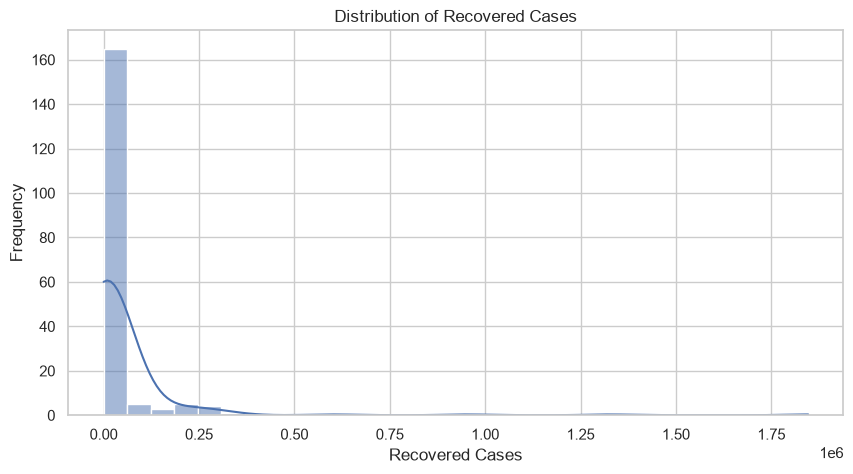

In [119]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Recovered"],
    bins=30,
    kde=True
)

plt.title("Distribution of Recovered Cases")
plt.xlabel("Recovered Cases")
plt.ylabel("Frequency")

plt.show()

Boxplot – Recovered

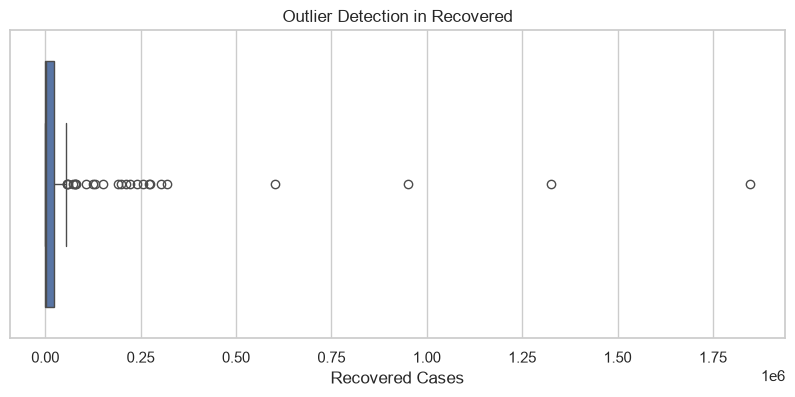

In [120]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Recovered"])

plt.title("Outlier Detection in Recovered")
plt.xlabel("Recovered Cases")

plt.show()

Top 10 countries based on recovered cases

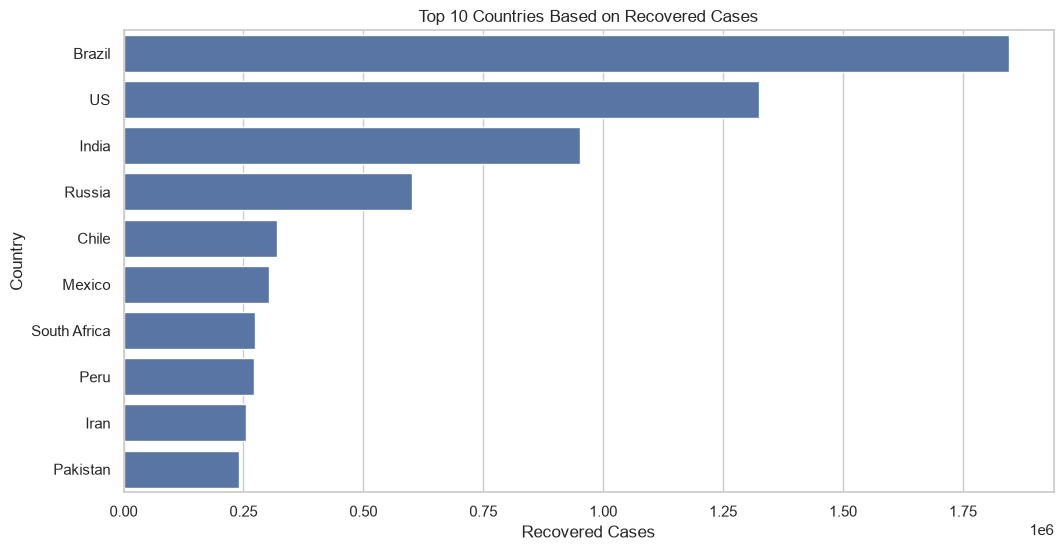

In [121]:
top_recovered = df.sort_values(
    by="Recovered",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_recovered,
    x="Recovered",
    y="Country/Region"
)

plt.title("Top 10 Countries Based on Recovered Cases")
plt.xlabel("Recovered Cases")
plt.ylabel("Country")

plt.show()

Relationship between Confirmed and Recovered

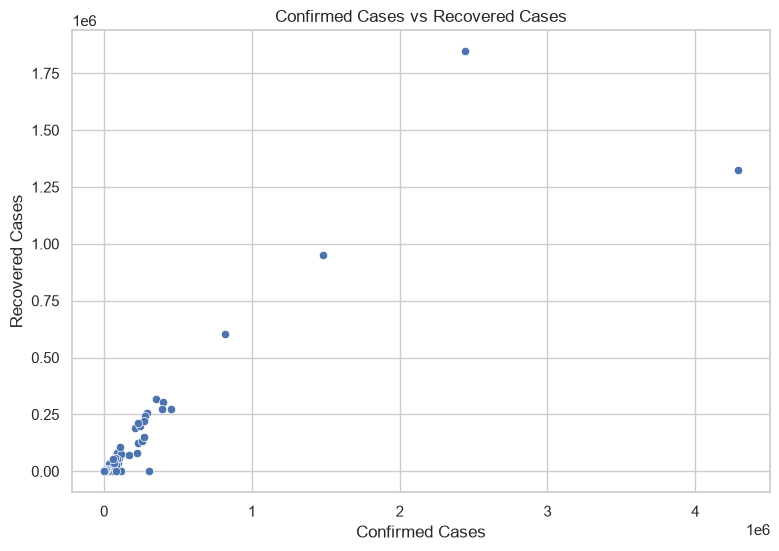

In [122]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Confirmed",
    y="Recovered"
)

plt.title("Confirmed Cases vs Recovered Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Recovered Cases")

plt.show()

Correlation heatmap

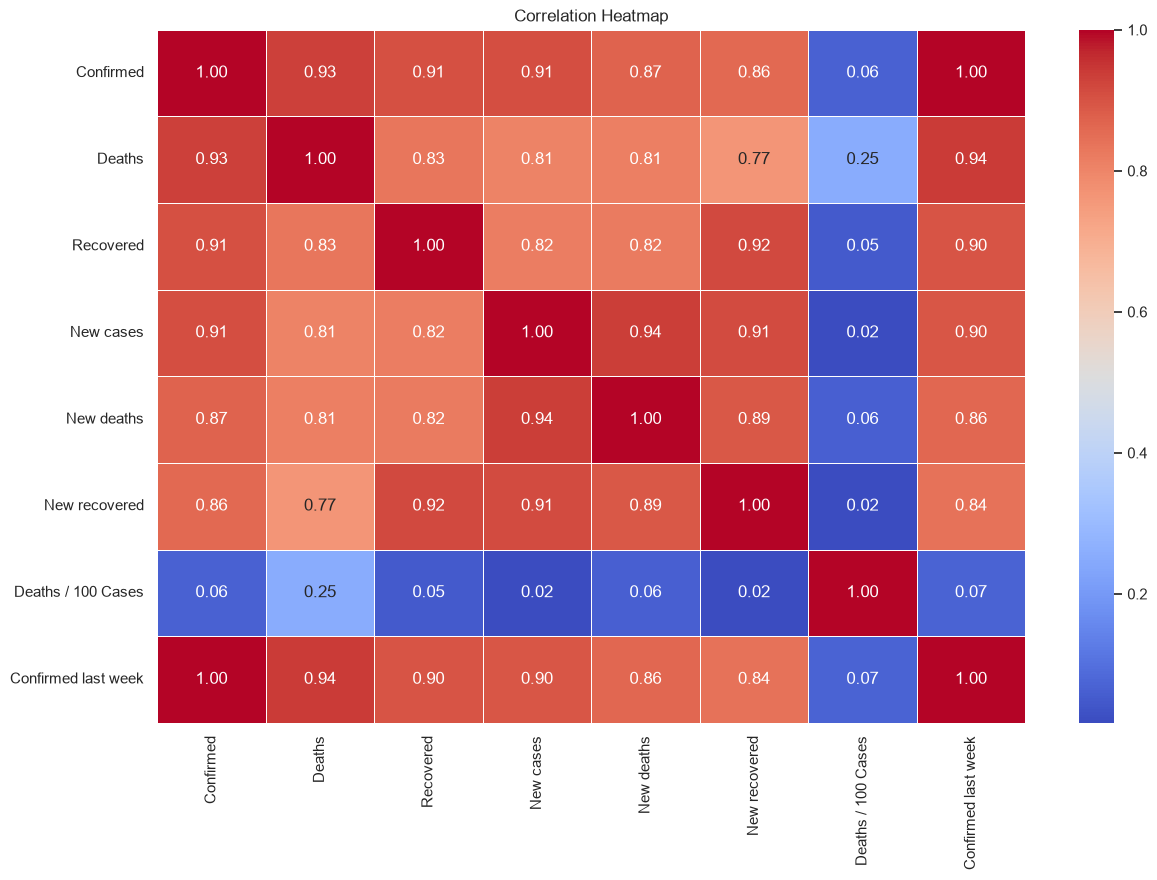

In [123]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

WHO region-wise recovery analysis

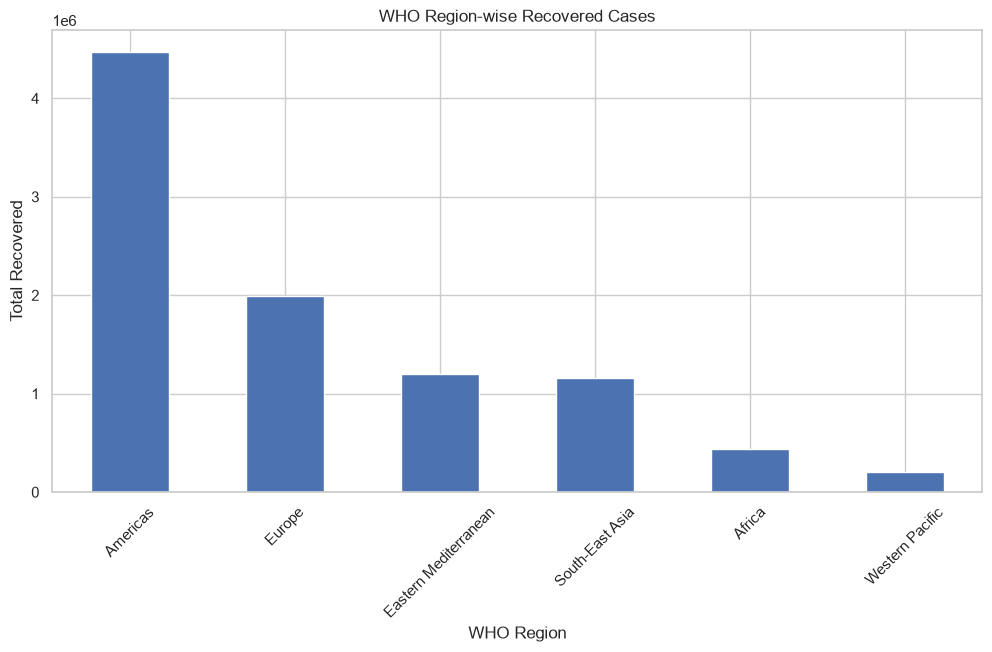

In [124]:
region_recovered = df.groupby("WHO Region")["Recovered"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

region_recovered.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("WHO Region-wise Recovered Cases")
plt.xlabel("WHO Region")
plt.ylabel("Total Recovered")
plt.xticks(rotation=45)

plt.show()

Compare Confirmed, Deaths and Recovered

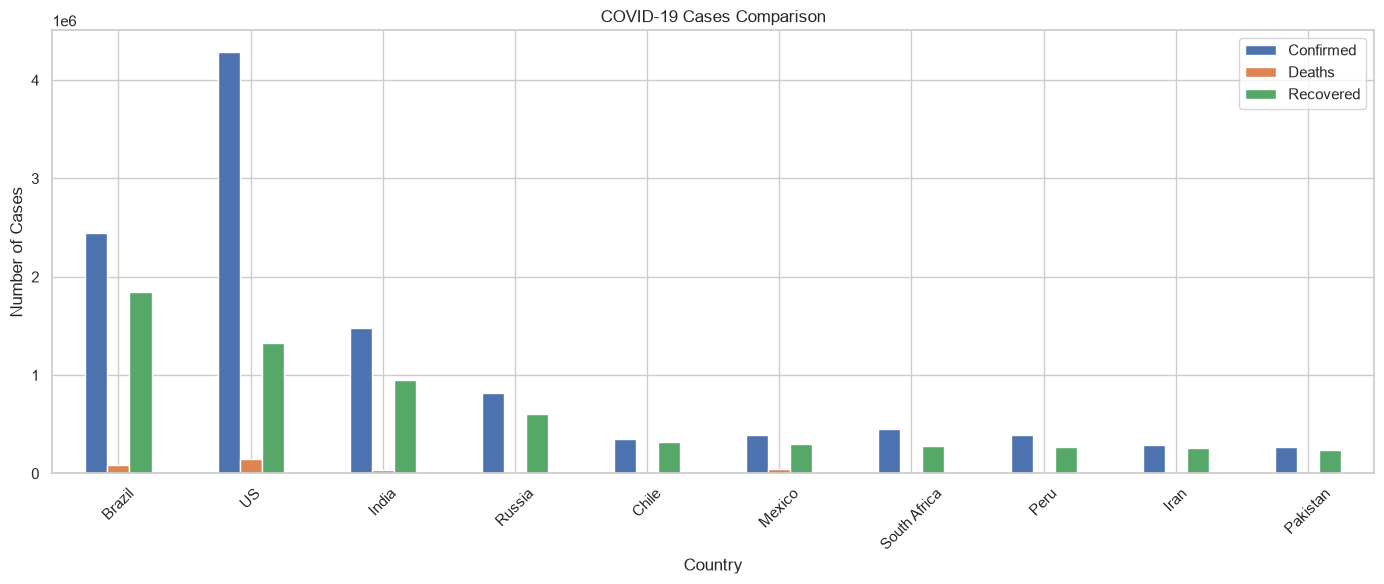

In [125]:
top_countries = df.nlargest(10, "Recovered")

top_countries.plot(
    x="Country/Region",
    y=["Confirmed", "Deaths", "Recovered"],
    kind="bar",
    figsize=(14, 6)
)

plt.title("COVID-19 Cases Comparison")
plt.xlabel("Country")
plt.ylabel("Number of Cases")
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()

Outlier detection using IQR

In [126]:
Q1 = df["Recovered"].quantile(0.25)
Q3 = df["Recovered"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Recovered"] < lower_limit) |
    (df["Recovered"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("Number of Outliers:", len(outliers))

display(outliers[["Country/Region", "Recovered"]])

Lower Limit: -32342.75
Upper Limit: 55575.25
Number of Outliers: 25


,Country/Region,Recovered
6,Argentina,72575
13,Bangladesh,125683
15,Belarus,60492
23,Brazil,1846641
35,Chile,319954
36,China,78869
37,Colombia,131161
61,France,81212
65,Germany,190314
79,India,951166


Log transformation visualization

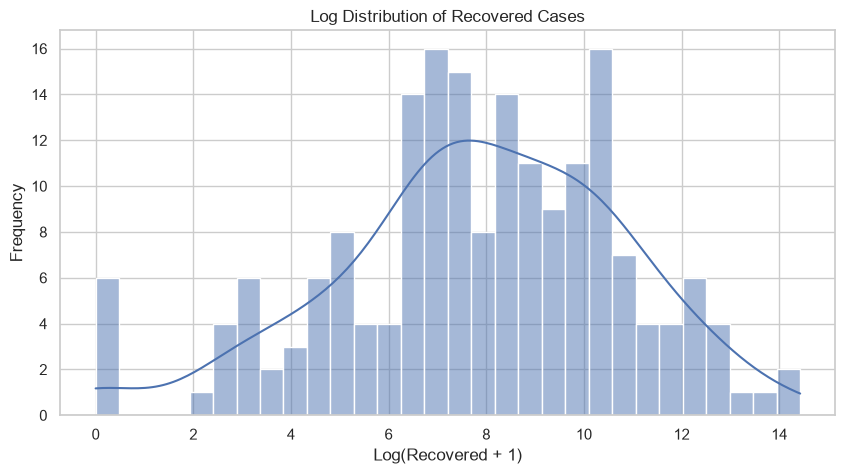

In [115]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df["Recovered"]),
    bins=30,
    kde=True
)

plt.title("Log Distribution of Recovered Cases")
plt.xlabel("Log(Recovered + 1)")
plt.ylabel("Frequency")

plt.show()

Check correlation with Recovered

In [127]:
recovered_corr = correlation["Recovered"].sort_values(
    ascending=False
)

print("Features correlated with Recovered:")
print(recovered_corr)

Features correlated with Recovered:
Recovered              1.000000
New recovered          0.919203
Confirmed              0.906377
Confirmed last week    0.899312
Deaths                 0.832098
New deaths             0.820338
New cases              0.818942
Deaths / 100 Cases     0.048438
Name: Recovered, dtype: float64


In [128]:
print("========== EDA SUMMARY ==========")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Total Recovered Cases:", df["Recovered"].sum())

print("Average Recovered Cases:", df["Recovered"].mean())

print("Maximum Recovered Cases:", df["Recovered"].max())

print("Minimum Recovered Cases:", df["Recovered"].min())

print("=================================")

========== EDA SUMMARY ==========
Total Rows: 187
Total Columns: 10
Missing Values: 0
Duplicate Rows: 0
Total Recovered Cases: 9468087
Average Recovered Cases: 50631.48128342246
Maximum Recovered Cases: 1846641
Minimum Recovered Cases: 0


Remove unnecessary columns

In [ ]:

df.drop(
    columns=["1 week change", "1 week % increase"],
    inplace=True,
    errors="ignore"
)

print(df.columns)

Index(['Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active',
       'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases',
       'Recovered / 100 Cases', 'Deaths / 100 Recovered',
       'Confirmed last week', 'WHO Region'],
      dtype='str')


Remove duplicate records

In [129]:
print("Before removing duplicates:", df.shape)

df.drop_duplicates(inplace=True)

print("After removing duplicates:", df.shape)

Before removing duplicates: (187, 10)
After removing duplicates: (187, 10)


Handle missing values

In [130]:
# Check missing values
print(df.isnull().sum())

# Numerical columns
numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Country/Region         0
Confirmed              0
Deaths                 0
Recovered              0
New cases              0
New deaths             0
New recovered          0
Deaths / 100 Cases     0
Confirmed last week    0
WHO Region             0
dtype: int64
Numerical Columns: ['Confirmed', 'Deaths', 'Recovered', 'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases', 'Confirmed last week']
Categorical Columns: ['Country/Region', 'WHO Region']


C:\Users\sandi\AppData\Local\Temp\ipykernel_14656\3471255927.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


Separate input and target variables

In [131]:
# Remove target-derived and leakage columns
leakage_columns = [
    "Recovered / 100 Cases",
    "Deaths / 100 Recovered",
    "Active"
]

df.drop(
    columns=leakage_columns,
    inplace=True,
    errors="ignore"
)

# Separate features and target
X = df.drop(columns=["Recovered"])

y = df["Recovered"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (187, 9)
y Shape: (187,)


Train-test split

In [57]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (149, 9)
X_test: (38, 9)
y_train: (149,)
y_test: (38,)


Numerical and categorical preprocessing

In [118]:
# Identify column types
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

# Numerical pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

C:\Users\sandi\AppData\Local\Temp\ipykernel_14656\3888483469.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Apply preprocessing

In [59]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (149, 162)
Testing data shape: (38, 162)


Save the preprocessor

In [62]:
joblib.dump(preprocessor, "preprocessor.pkl")

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


Save processed datasets

In [63]:
# Convert sparse matrices to dense arrays if needed
X_train_array = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_array = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

# Save files
np.save("X_train.npy", X_train_array)
np.save("X_test.npy", X_test_array)

np.save("y_train.npy", y_train.to_numpy())
np.save("y_test.npy", y_test.to_numpy())

print("All processed datasets saved successfully!")

All processed datasets saved successfully!


Final verification

In [64]:
print("========== PREPROCESSING SUMMARY ==========")

print("Training Samples:", X_train_processed.shape[0])
print("Testing Samples:", X_test_processed.shape[0])

print("Number of Features:", X_train_processed.shape[1])

print("Missing Values in y_train:", y_train.isnull().sum())
print("Missing Values in y_test:", y_test.isnull().sum())

print("Target Mean:", y_train.mean())

print("===========================================")

========== PREPROCESSING SUMMARY ==========
Training Samples: 149
Testing Samples: 38
Number of Features: 162
Missing Values in y_train: 0
Missing Values in y_test: 0
Target Mean: 48957.12751677852


In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [66]:
# Create a copy
df_fe = df.copy()

# Confirmed cases per country
df_fe["Total_Cases"] = df_fe["Confirmed"]

# Death percentage among confirmed cases
df_fe["Death_Rate"] = (
    df_fe["Deaths"] /
    df_fe["Confirmed"].replace(0, np.nan)
) * 100

# New cases percentage
df_fe["New_Cases_Rate"] = (
    df_fe["New cases"] /
    df_fe["Confirmed"].replace(0, np.nan)
) * 100

# New deaths percentage
df_fe["New_Deaths_Rate"] = (
    df_fe["New deaths"] /
    df_fe["Confirmed"].replace(0, np.nan)
) * 100

# Case growth relative to existing confirmed cases
df_fe["Case_Growth"] = np.log1p(
    df_fe["New cases"].clip(lower=0)
)

print(df_fe.head())

  Country/Region  Confirmed  Deaths  Recovered  New cases  New deaths  \
0    Afghanistan      36263    1269      25198        106          10   
1        Albania       4880     144       2745        117           6   
2        Algeria      27973    1163      18837        616           8   
3        Andorra        907      52        803         10           0   
4         Angola        950      41        242         18           1   

   New recovered  Deaths / 100 Cases  Confirmed last week  \
0             18                3.50                35526   
1             63                2.95                 4171   
2            749                4.16                23691   
3              0                5.73                  884   
4              0                4.32                  749   

              WHO Region  Total_Cases  Death_Rate  New_Cases_Rate  \
0  Eastern Mediterranean        36263    3.499435        0.292309   
1                 Europe         4880    2.950820       

Remove unnecessary and leakage columns

In [68]:
# Columns not suitable as predictors
remove_columns = [
    "Country/Region",
    "Confirmed",
    "Deaths",
    "Recovered",
    "Active",
    "Recovered / 100 Cases",
    "Deaths / 100 Recovered",
    "1 week change",
    "1 week % increase"
]

X_fe = df_fe.drop(
    columns=remove_columns,
    errors="ignore"
)

y = df_fe["Recovered"]

print("Feature Engineering Shape:", X_fe.shape)

display(X_fe.head())

Feature Engineering Shape: (187, 11)


,New cases,New deaths,New recovered,Deaths / 100 Cases,Confirmed last week,WHO Region,Total_Cases,Death_Rate,New_Cases_Rate,New_Deaths_Rate,Case_Growth
0,106,10,18,3.50,35526,Eastern Mediterranean,36263,3.499435,0.292309,0.027576,4.672829
1,117,6,63,2.95,4171,Europe,4880,2.950820,2.397541,0.122951,4.770685
2,616,8,749,4.16,23691,Africa,27973,4.157581,2.202123,0.028599,6.424869
3,10,0,0,5.73,884,Europe,907,5.733186,1.102536,0.000000,2.397895
4,18,1,0,4.32,749,Africa,950,4.315789,1.894737,0.105263,2.944439


Check feature correlations

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = X_fe.select_dtypes(
    include=np.number
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_features.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Engineering Correlation Heatmap")

plt.show()

C:\Users\sandi\AppData\Local\Temp\ipykernel_14656\3412210113.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Check newly created features

In [70]:
print("Engineered Features:")

for column in X_fe.columns:
    print(column)

Engineered Features:
New cases
New deaths
New recovered
Deaths / 100 Cases
Confirmed last week
WHO Region
Total_Cases
Death_Rate
New_Cases_Rate
New_Deaths_Rate
Case_Growth


Separate numerical and categorical features

In [71]:
# Select numerical columns
X_numeric = X_fe.select_dtypes(
    include=np.number
)

# Handle missing values
X_numeric = X_numeric.fillna(
    X_numeric.median()
)

print("Before PCA:", X_numeric.shape)

Before PCA: (187, 10)


Apply StandardScaler

In [72]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_numeric)

print("Scaled Shape:", X_scaled.shape)

Scaled Shape: (187, 10)


Apply PCAv

In [73]:
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original Features:", X_scaled.shape[1])

print("Features After PCA:", X_pca.shape[1])

print("PCA Shape:", X_pca.shape)

Original Features: 10
Features After PCA: 5
PCA Shape: (187, 5)


Check explained variance

In [74]:
explained_variance = pca.explained_variance_ratio_

print("Explained Variance:", explained_variance)

print(
    "Total Explained Variance:",
    sum(explained_variance)
)

Explained Variance: [0.48761132 0.204745   0.17644187 0.06344759 0.02969162]
Total Explained Variance: 0.9619373913912365


In [75]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% Variance"
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.legend()
plt.grid()

plt.show()

C:\Users\sandi\AppData\Local\Temp\ipykernel_14656\3135586086.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [76]:
pca_columns = [
    f"PC{i+1}"
    for i in range(X_pca.shape[1])
]

X_pca_df = pd.DataFrame(
    X_pca,
    columns=pca_columns,
    index=X_fe.index
)

print(X_pca_df.head())

        PC1       PC2       PC3       PC4       PC5
0 -0.306947  0.282579 -0.274365  0.389559 -0.428202
1 -0.230837  0.245555  1.464750 -0.224966 -0.681777
2  0.006313  0.505238  0.546844  0.844581  0.173451
3 -0.599076  1.040606 -0.581182 -0.221651  0.408635
4 -0.439688  0.732280  0.870075 -0.695355 -0.480904


In [77]:
import joblib

joblib.dump(scaler, "feature_scaler.pkl")

joblib.dump(pca, "pca_model.pkl")

joblib.dump(
    pca_columns,
    "pca_feature_names.pkl"
)

print("Scaler and PCA models saved successfully!")

Scaler and PCA models saved successfully!


In [78]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

Train-test split

In [79]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (149, 9)
Testing Data: (38, 9)


Apply preprocessing pipeline

In [81]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

C:\Users\sandi\AppData\Local\Temp\ipykernel_14656\4288476906.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Select machine learning models

In [84]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

Train all models and evaluate

In [85]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluation
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Model: Linear Regression
MAE: 33330.17535806038
RMSE: 70948.90889744193
R2 Score: 0.6590125855092159

Model: Decision Tree
MAE: 28099.605263157893
RMSE: 78036.57448459326
R2 Score: 0.5874816210581163

Model: Random Forest
MAE: 24930.106418206095
RMSE: 66582.5531769751
R2 Score: 0.6996913807362639

Model: Gradient Boosting
MAE: 23683.376244847503
RMSE: 55896.19272525625
R2 Score: 0.788353367263077


Compare model performance

In [86]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
3,Gradient Boosting,23683.376245,3.124384e+09,55896.192725,0.788353
2,Random Forest,24930.106418,4.433236e+09,66582.553177,0.699691
0,Linear Regression,33330.175358,5.033748e+09,70948.908897,0.659013
1,Decision Tree,28099.605263,6.089707e+09,78036.574485,0.587482


Visualize model comparison

In [87]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("ML Models")
plt.ylabel("RMSE")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

C:\Users\sandi\AppData\Local\Temp\ipykernel_14656\1025926823.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [88]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Gradient Boosting


Save the best model

In [89]:
joblib.dump(
    best_model,
    "best_recovered_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


Load the saved model

In [90]:
loaded_model = joblib.load(
    "best_recovered_model.pkl"
)

predictions = loaded_model.predict(X_test)

print("Predicted Recovered Cases:")

print(predictions[:10])

Predicted Recovered Cases:
[  4669.61520092   3081.14589179   3081.14589179  27054.12663582
  44031.88692179  37892.22184422   3081.14589179 270155.65133199
   3183.00310413  39241.63331818]


In [91]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

In [92]:
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Model training
    pipeline.fit(X_train, y_train)

    # Store trained model
    trained_models[name] = pipeline

    print(name, "Training Completed!")


Training: Linear Regression
Linear Regression Training Completed!

Training: Decision Tree
Decision Tree Training Completed!

Training: Random Forest
Random Forest Training Completed!

Training: Gradient Boosting
Gradient Boosting Training Completed!


In [93]:
results = []

for name, model in trained_models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("RMSE"))

,Model,MAE,MSE,RMSE,R2 Score
3,Gradient Boosting,23683.376245,3.124384e+09,55896.192725,0.788353
2,Random Forest,24930.106418,4.433236e+09,66582.553177,0.699691
0,Linear Regression,33330.175358,5.033748e+09,70948.908897,0.659013
1,Decision Tree,29994.552363,5.473203e+09,73981.098873,0.629244


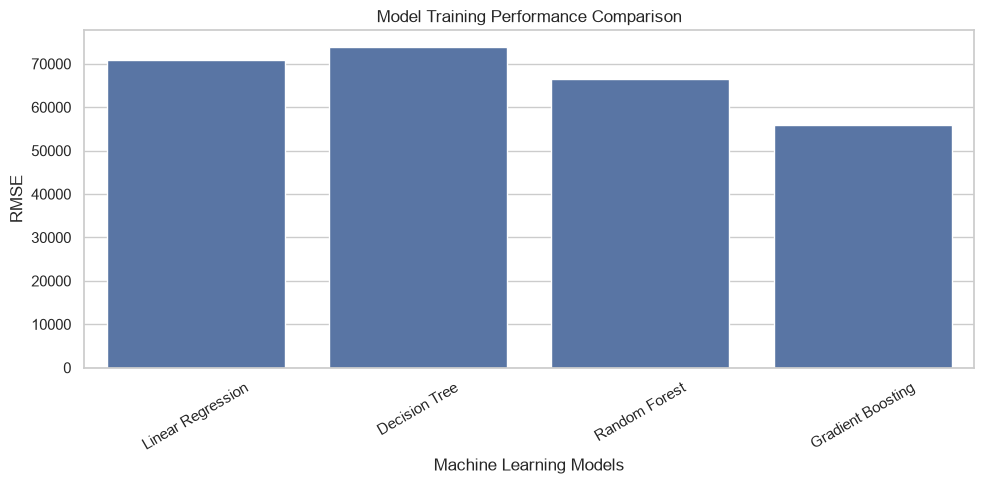

In [98]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Training Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [102]:

model = joblib.load("best_recovered_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!
